# Searching for TOI-178 candidates
TOI-178 is a complex system with six confirmed orbiting
planets (Leleu et al. 2021), where the five outer members do it
under mean motion resonances. The SPOC reported up to three TOIs
(TOI-178.01 -6.56 d-, TOI-178.02 -10.35 d- and TOI-178.03 -9.96 d-).
In Leleu et al. (2021) a much deeper search was done by using, among
others, the CHEOPS satellite, which provides ultra-precise
photometry. As a surprise, three new candidates were identified
with periods of 1.92, 3.95 and 15.5 days each and giving a new
period value of 20.7 (twice the initial value) to the TOI-178.02.

We will run SHERLOCK to see what we can find under the TESS data
for this very interesting system. Let's go!

We firstly initialize the object to be searched for with a `MissionObjectInfo`
and the `Sherlock` main object used for the execution.

In [1]:
import os
import multiprocessing
from lcbuilder import constants
from sherlockpipe.search.sherlock import Sherlock
from lcbuilder.objectinfo.MissionObjectInfo import MissionObjectInfo
from sherlockpipe.search.sherlock_target import SherlockTarget

toi178_object_info = MissionObjectInfo([2], "TIC 251848941",
                                        author=[constants.SPOC_AUTHOR], cadence=[120])
toi178_sherlock_target = SherlockTarget(object_info=toi178_object_info, detrends_number=4,
                                        period_min=0.45, period_max=22, cpu_cores=multiprocessing.cpu_count() - 1,
                                        best_signal_algorithm="quorum", min_quorum=0.5)
sherlock = Sherlock([toi178_sherlock_target], False)

/home/tienesunklip/miniconda3/envs/sherlock311/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.4.0) or chardet (7.5.1)/charset_normalizer (3.5.0) doesn't match a supported version!
  warnings.warn(


/home/tienesunklip/miniconda3/envs/sherlock311/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


/home/tienesunklip/miniconda3/envs/sherlock311/lib/python3.11/site-packages/lightkurve/config/__init__.py:119: UserWarning: The default Lightkurve cache directory, used by download(), etc., has been moved to /home/tienesunklip/.lightkurve/cache. Please move all the files in the legacy directory /home/tienesunklip/.lightkurve-cache to the new location and remove the legacy directory. Refer to https://docs.lightkurve.org/reference/config.html#default-cache-directory-migration for more information.
  warnings.warn(


2026-08-16 17:44:25.220807: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-08-16 17:44:25.231662: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1786895065.244118   22846 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1786895065.248009   22846 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1786895065.259540   22846 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

DONE


We choose the next parameters:

* The `MissionObjectInfo` is initialized with the TIC of the TOI-178 and we will only
search data from the sector nº 2.
* A number of detrends to be used of 4. This is generally a low value
and for real executions we will use even more than 10 detrends, but it will serve for the
example.
* A search grid between the period range of 0.45 and 22 (we only count with one sector).
* Use all the cpu cores but one.
* Finally, we choose to use the `quorum` algorithm, which in addition to the `min_quorum`
value set to 0.5 will stop the execution as soon as the found `Sherlock` signals in
the last run do not agree with more than the half of the votes.

Let's run it and see what happens.

In [2]:
if not os.path.exists('TIC251848941_[2]/1'):
    sherlock.run()

Ok it seems that Sherlock already finished. From the output we can read that `Sherlock`
executed 7 runs. That means the it found 6 runs with a good quorum (the last one was not
very promising and therefore the execution finished. Knowing that, we will inspect the
best results from each run.

We will start from the beginning, of course. We will inspect the results of the first run:

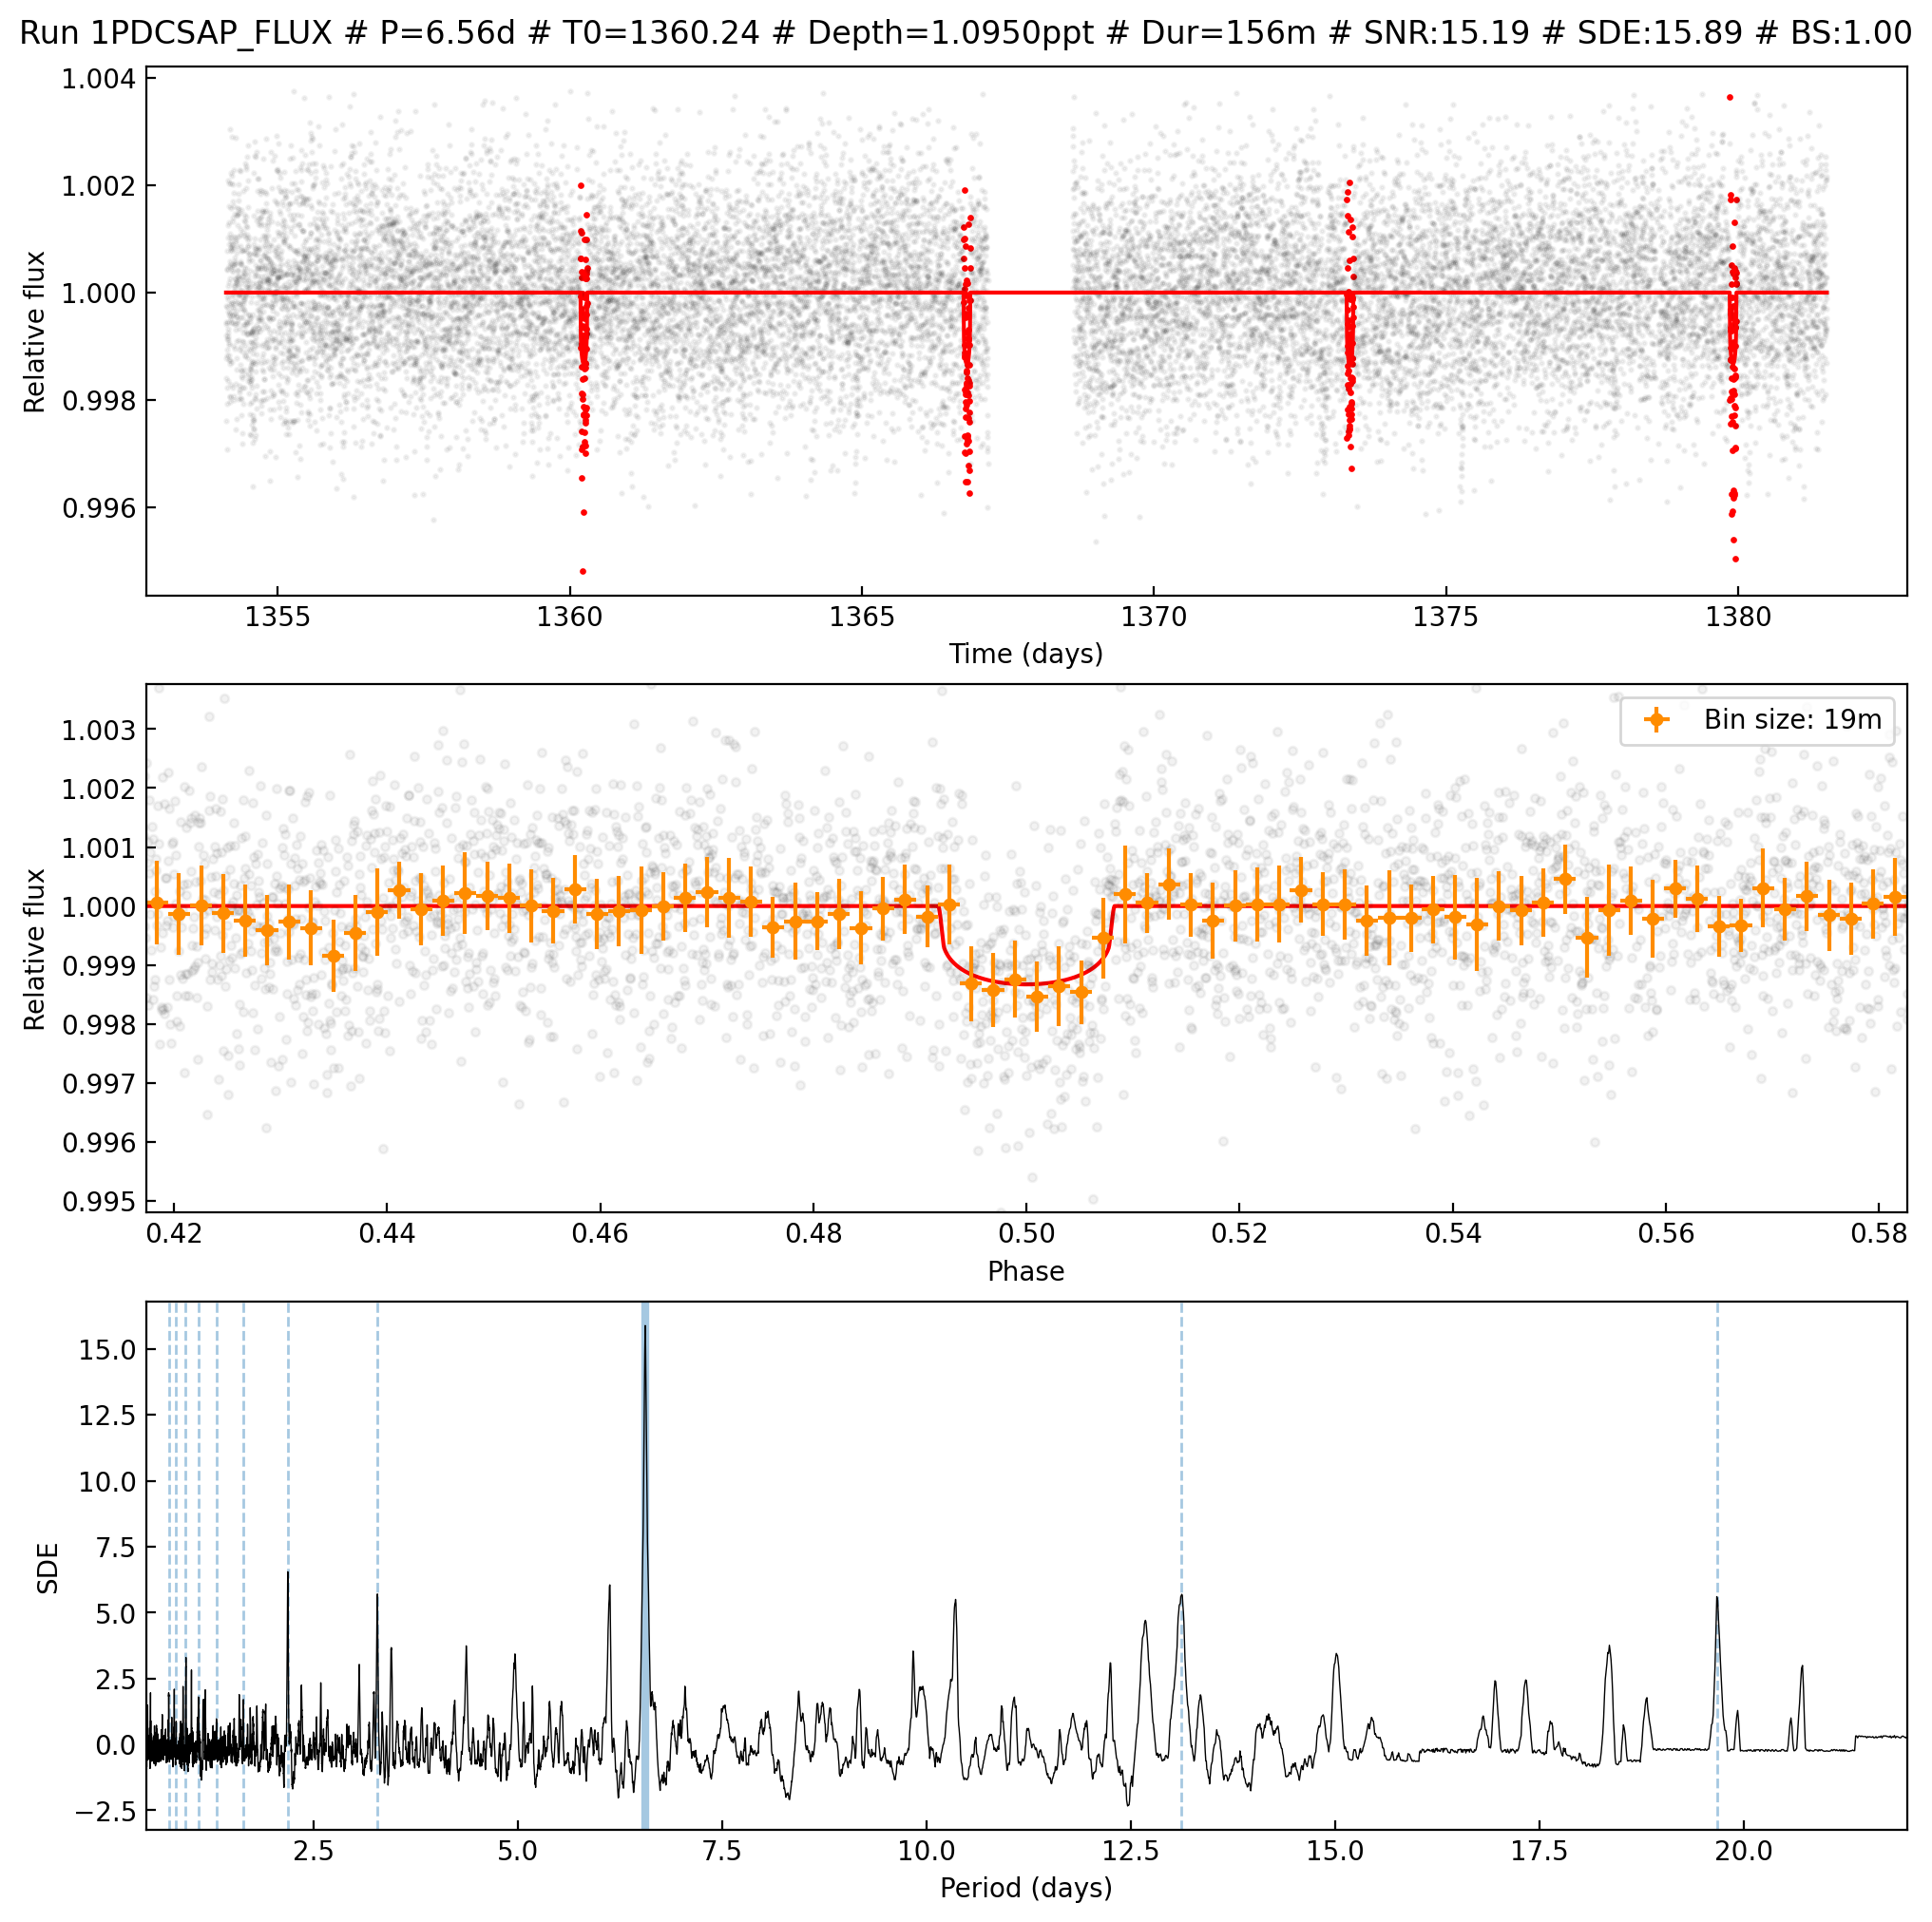

In [3]:
your_execution_dir = os.getcwd()
import glob
file_image = sorted(glob.glob(glob.escape(your_execution_dir + '/TIC251848941_[2]') + '/*/*.png'))[0]
from IPython.display import Image
Image(filename=file_image)

Well, we can be sure that we have already retrieved the TOI-178.01 with P=6.56d in the
first run. We could then inspect the second one:

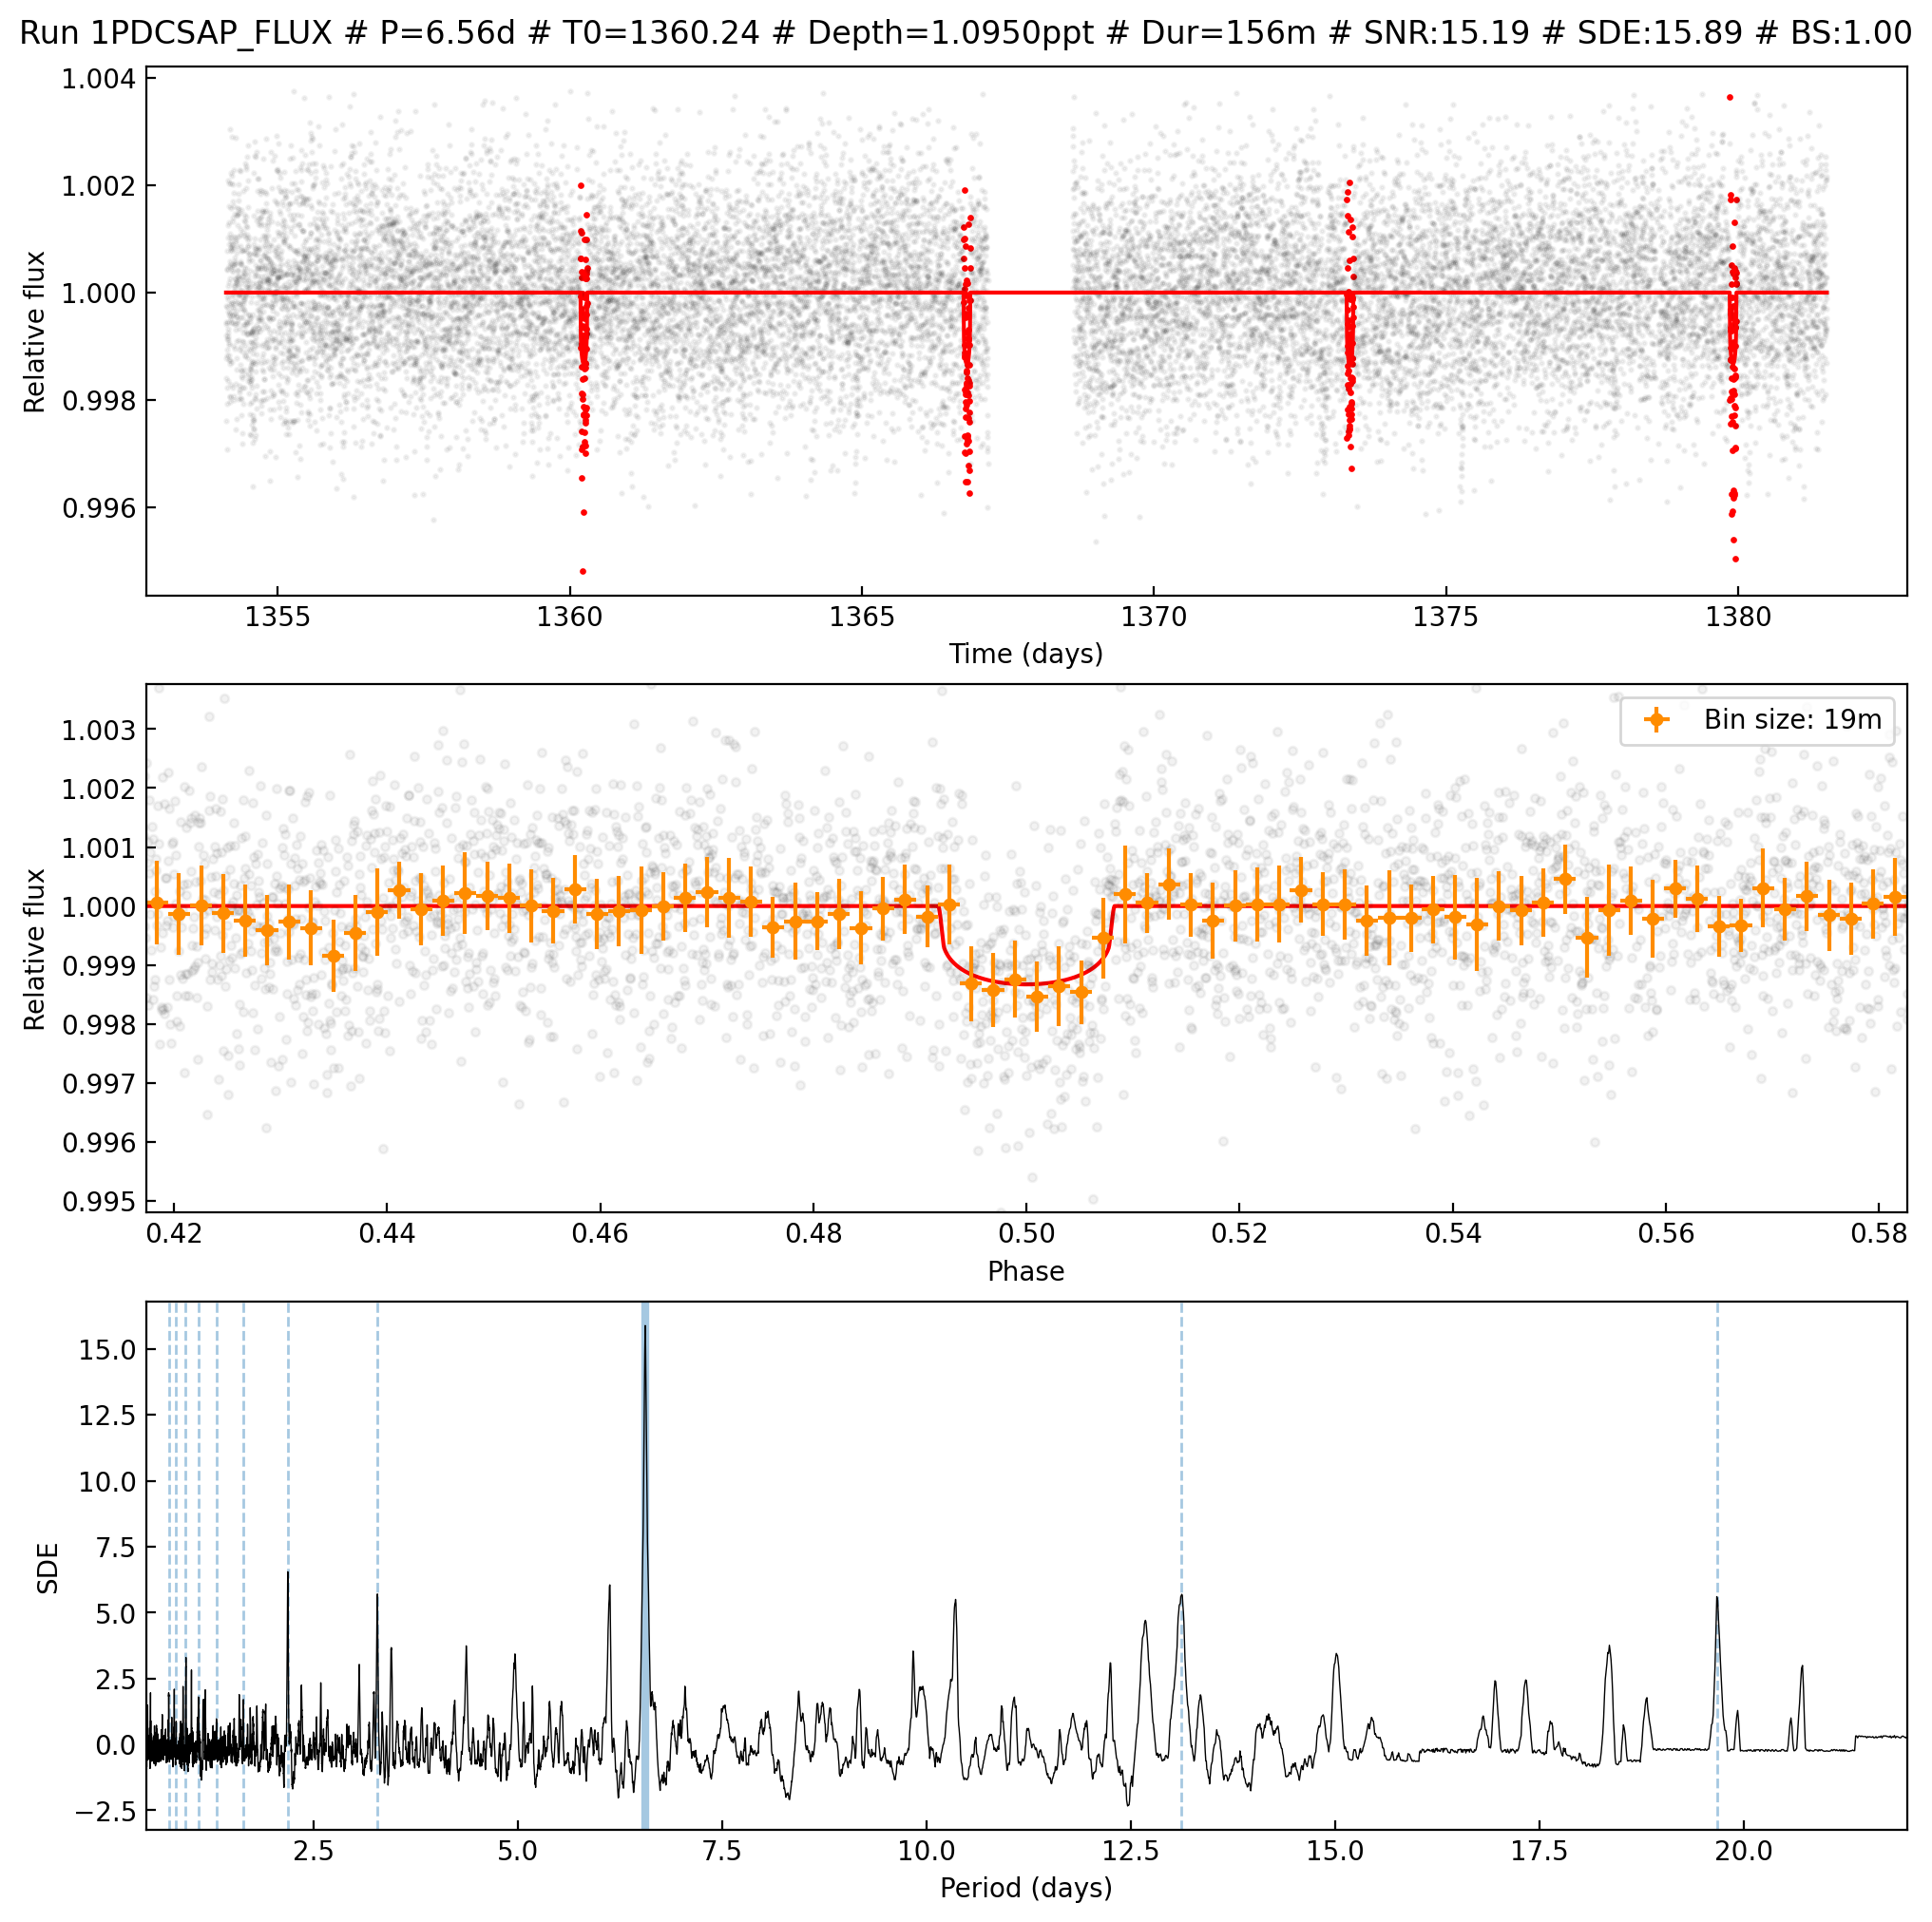

In [4]:
import glob
file_image = sorted(glob.glob(glob.escape(your_execution_dir + '/TIC251848941_[2]') + '/*/*.png'))[0]
from IPython.display import Image
Image(filename=file_image)

We found the TOI-178.02! If we look into Leleu et al. (2021) we will see that the found
period of P=10.35d matches with the P=20.7d planet found there. This seems to be happening
because we are inspecting only one sector and as a consequence we cannot find periods greater
than 13 days approximately.

Ok, assuming we are doing it fine, we can continue our search for the next candidate:

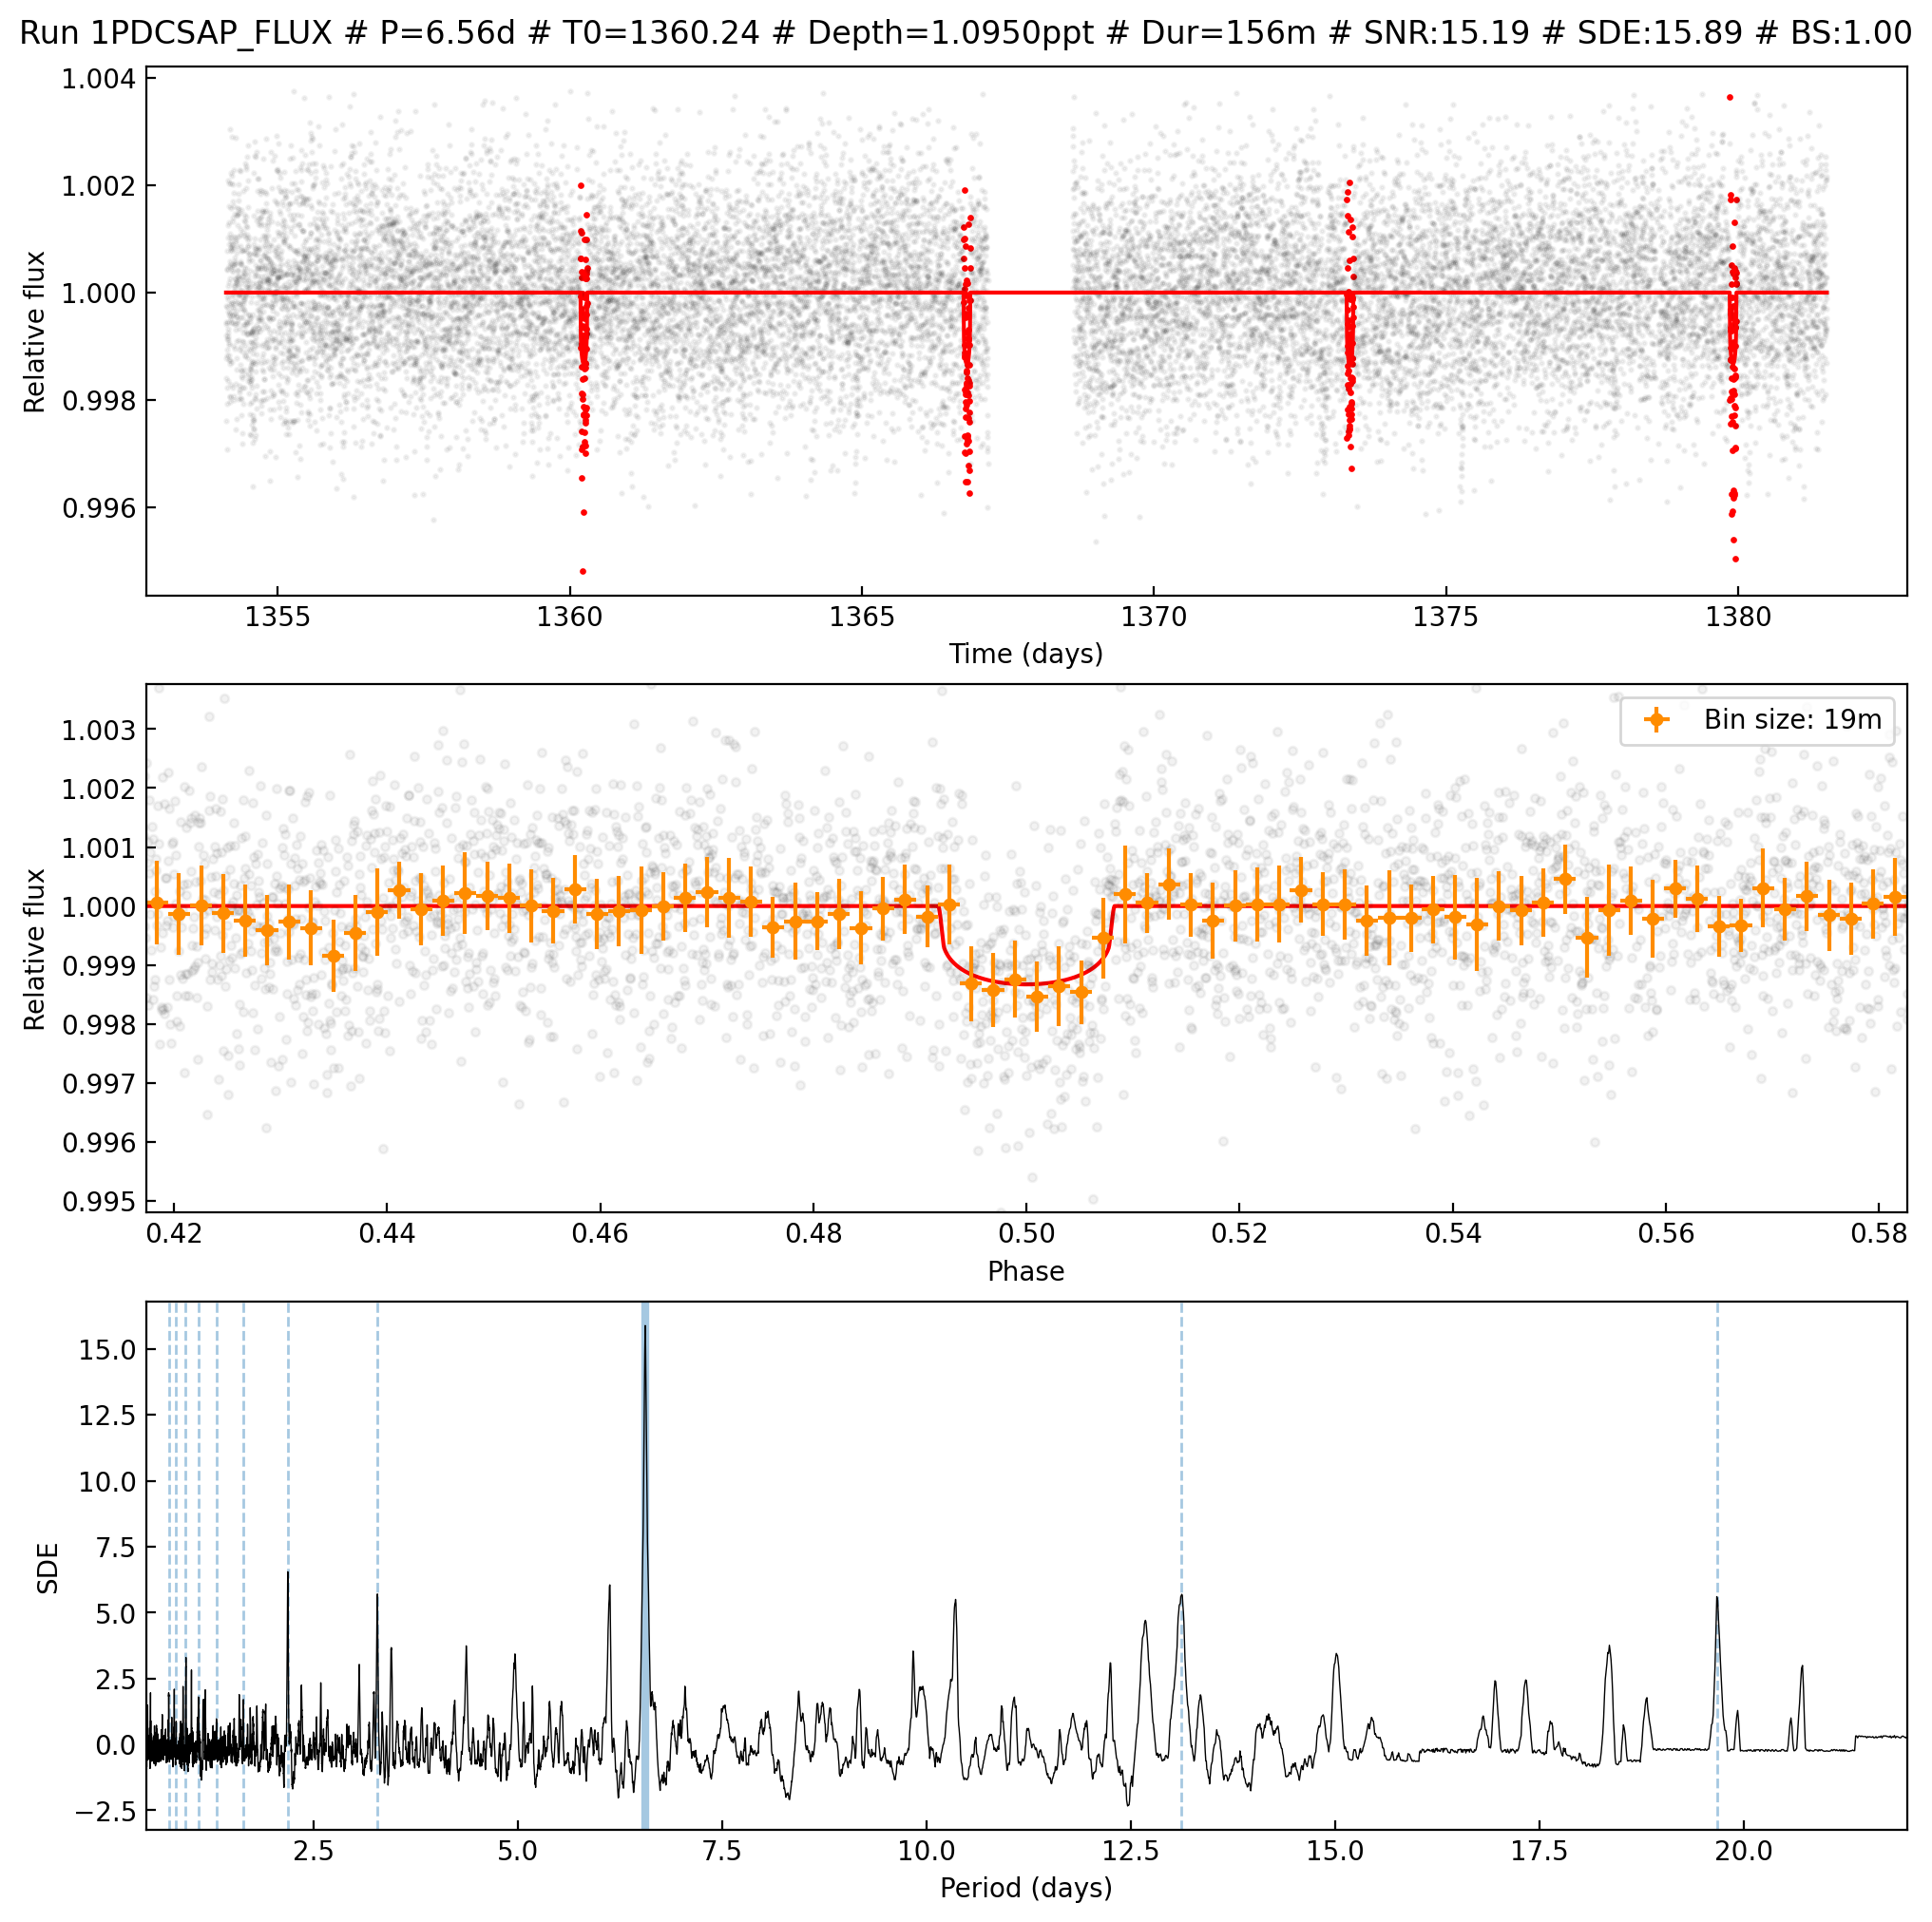

In [5]:
import glob
file_image = sorted(glob.glob(glob.escape(your_execution_dir + '/TIC251848941_[2]') + '/*/*.png'))[0]
from IPython.display import Image
Image(filename=file_image)

We are finding a candidate with a P=4.96d. That matches with the TOI-178.03 with P=9.95. It
is not clear we we would be finding the first subharmonic first than the real transit, but
we can see that the real period was also very strong in the power spectrum. We have detected
the three candidates from the official TESS pipeline SPOC. But wait! Do you remember that
`Sherlock` returned up to 6 promising runs? Let's have a look at them:

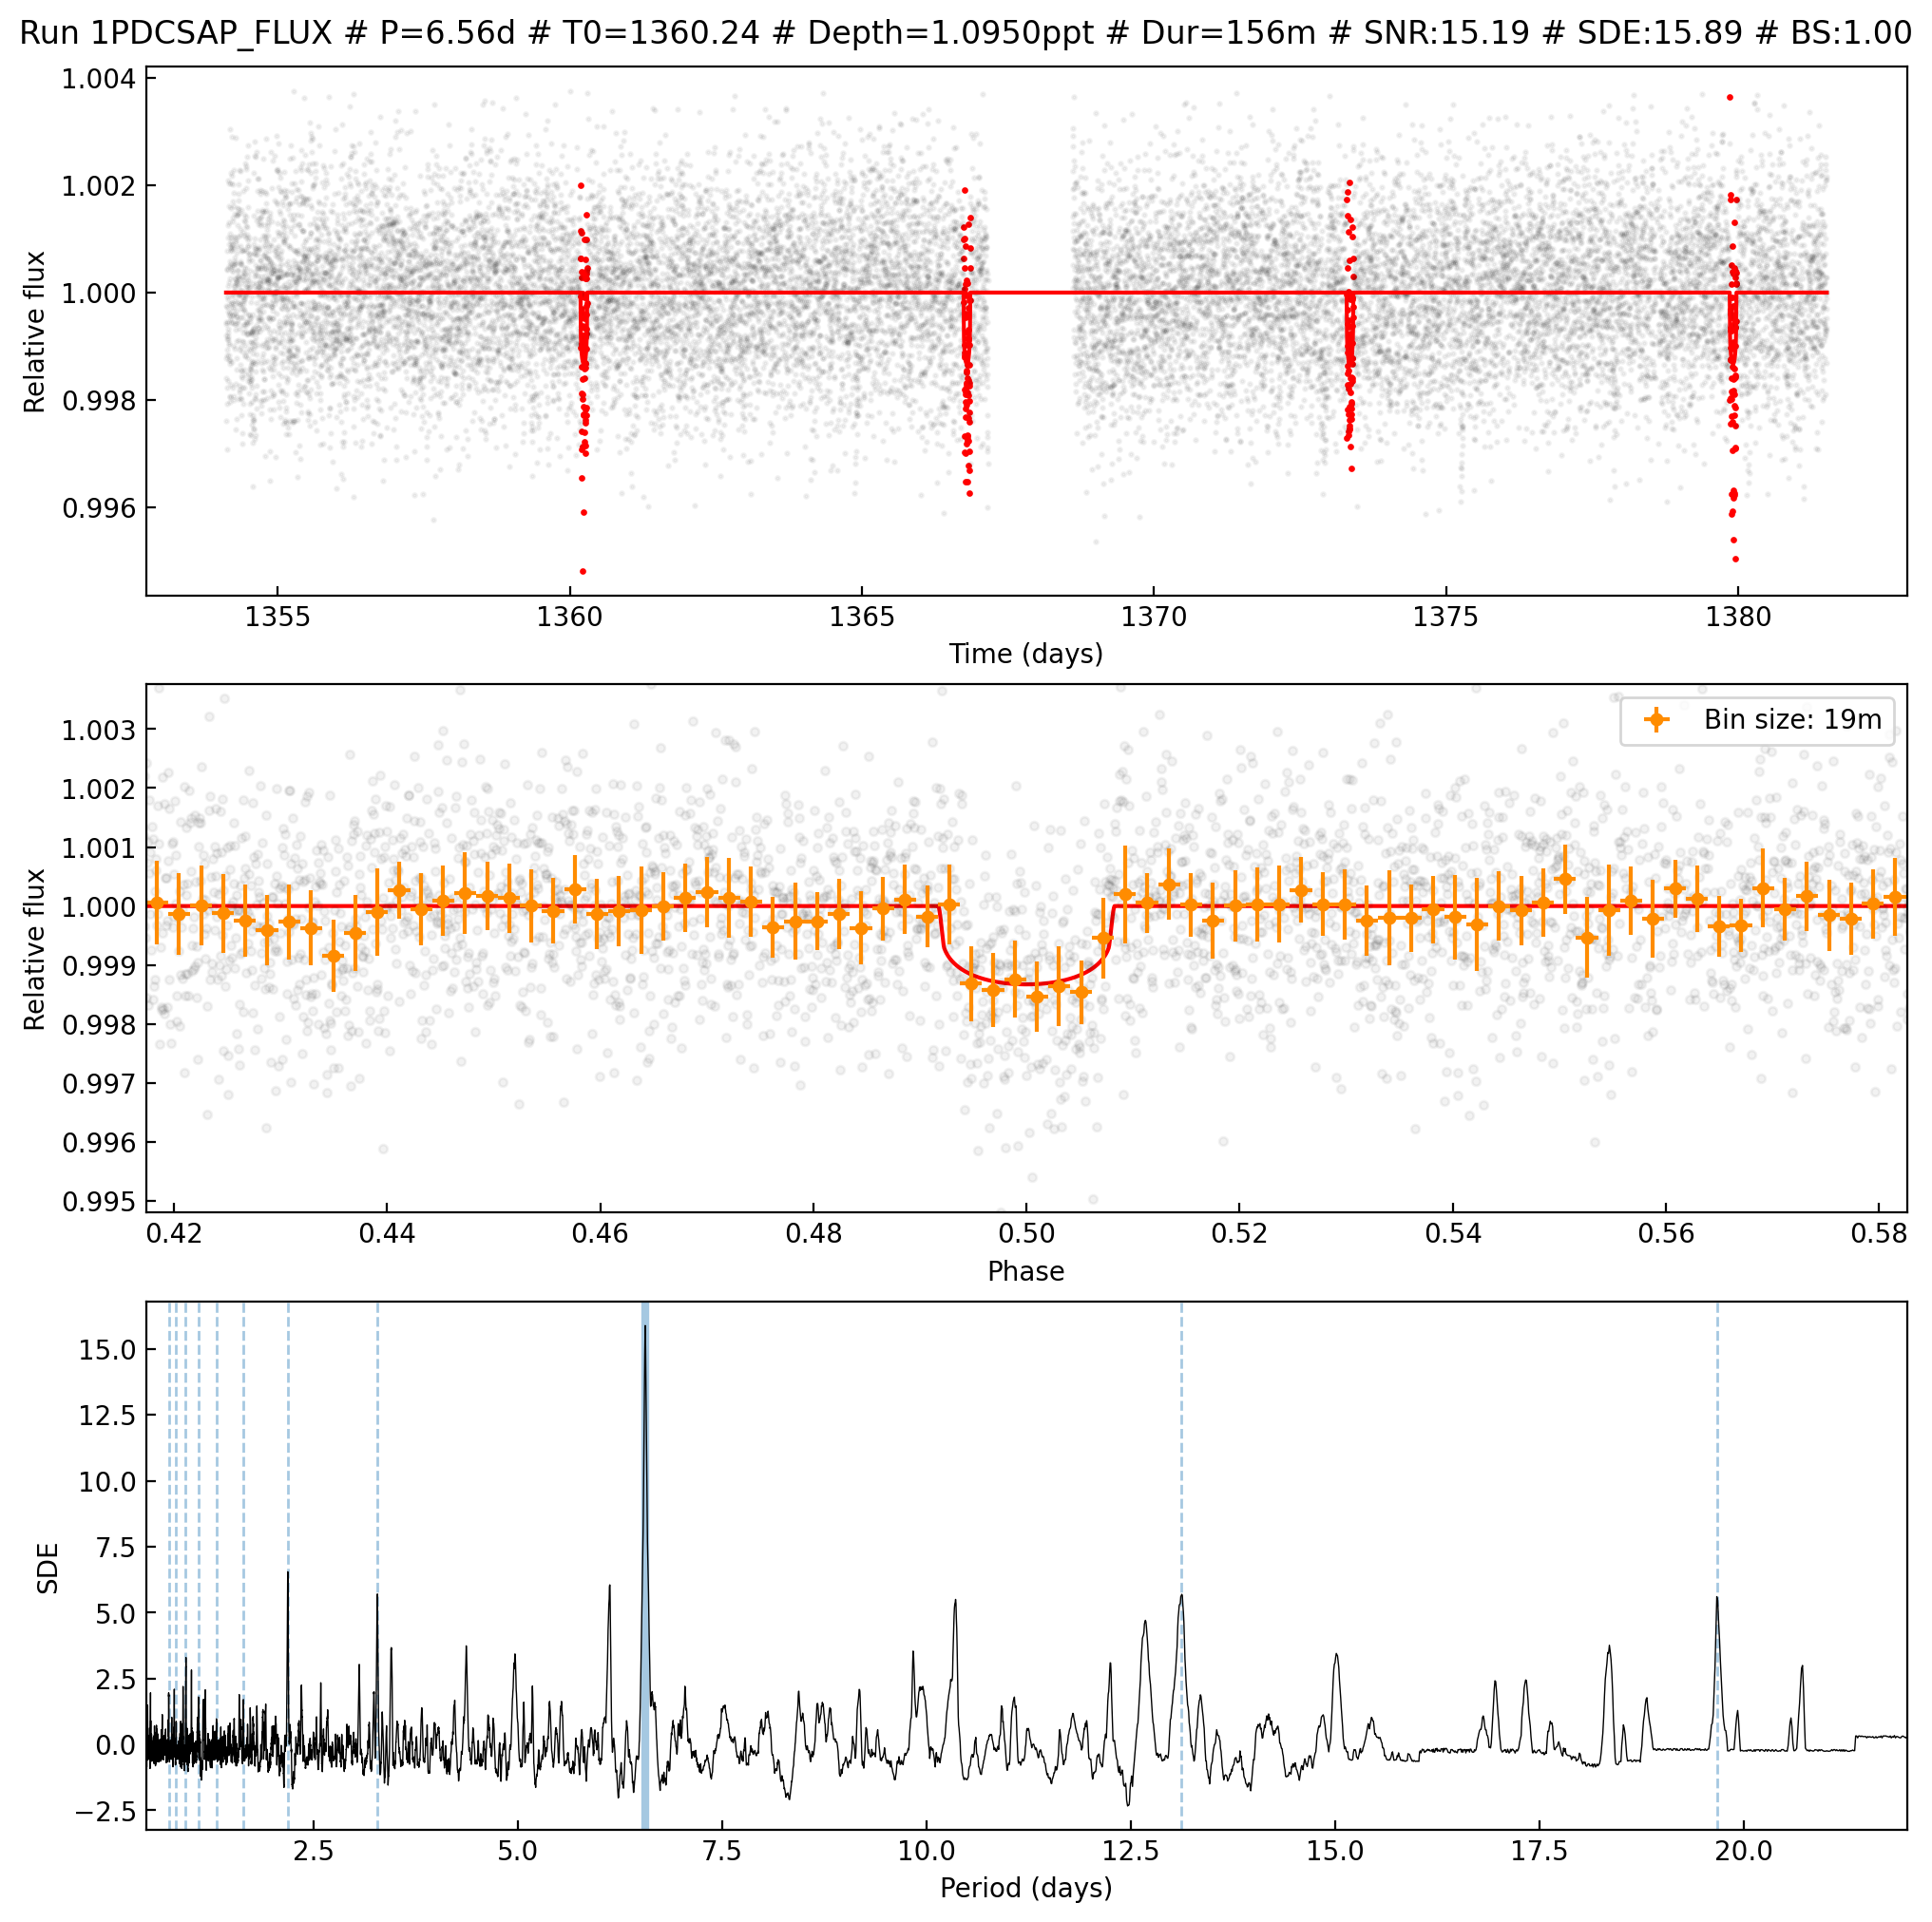

In [6]:
import glob
file_image = sorted(glob.glob(glob.escape(your_execution_dir + '/TIC251848941_[2]') + '/*/*.png'))[0]
from IPython.display import Image
Image(filename=file_image)


This is a candidate with P=3.24d. Wow! It seems that we are finding one of the new confirmed
planets from Leleu et al. (2021) that wasn't alerted by the SPOC! And we did it only from the
TESS data (no CHEOPS nor RVs data). And look at the SNR, it is still very high!

Well, we have two promising runs to analyze yet. Let's see the 5th run:

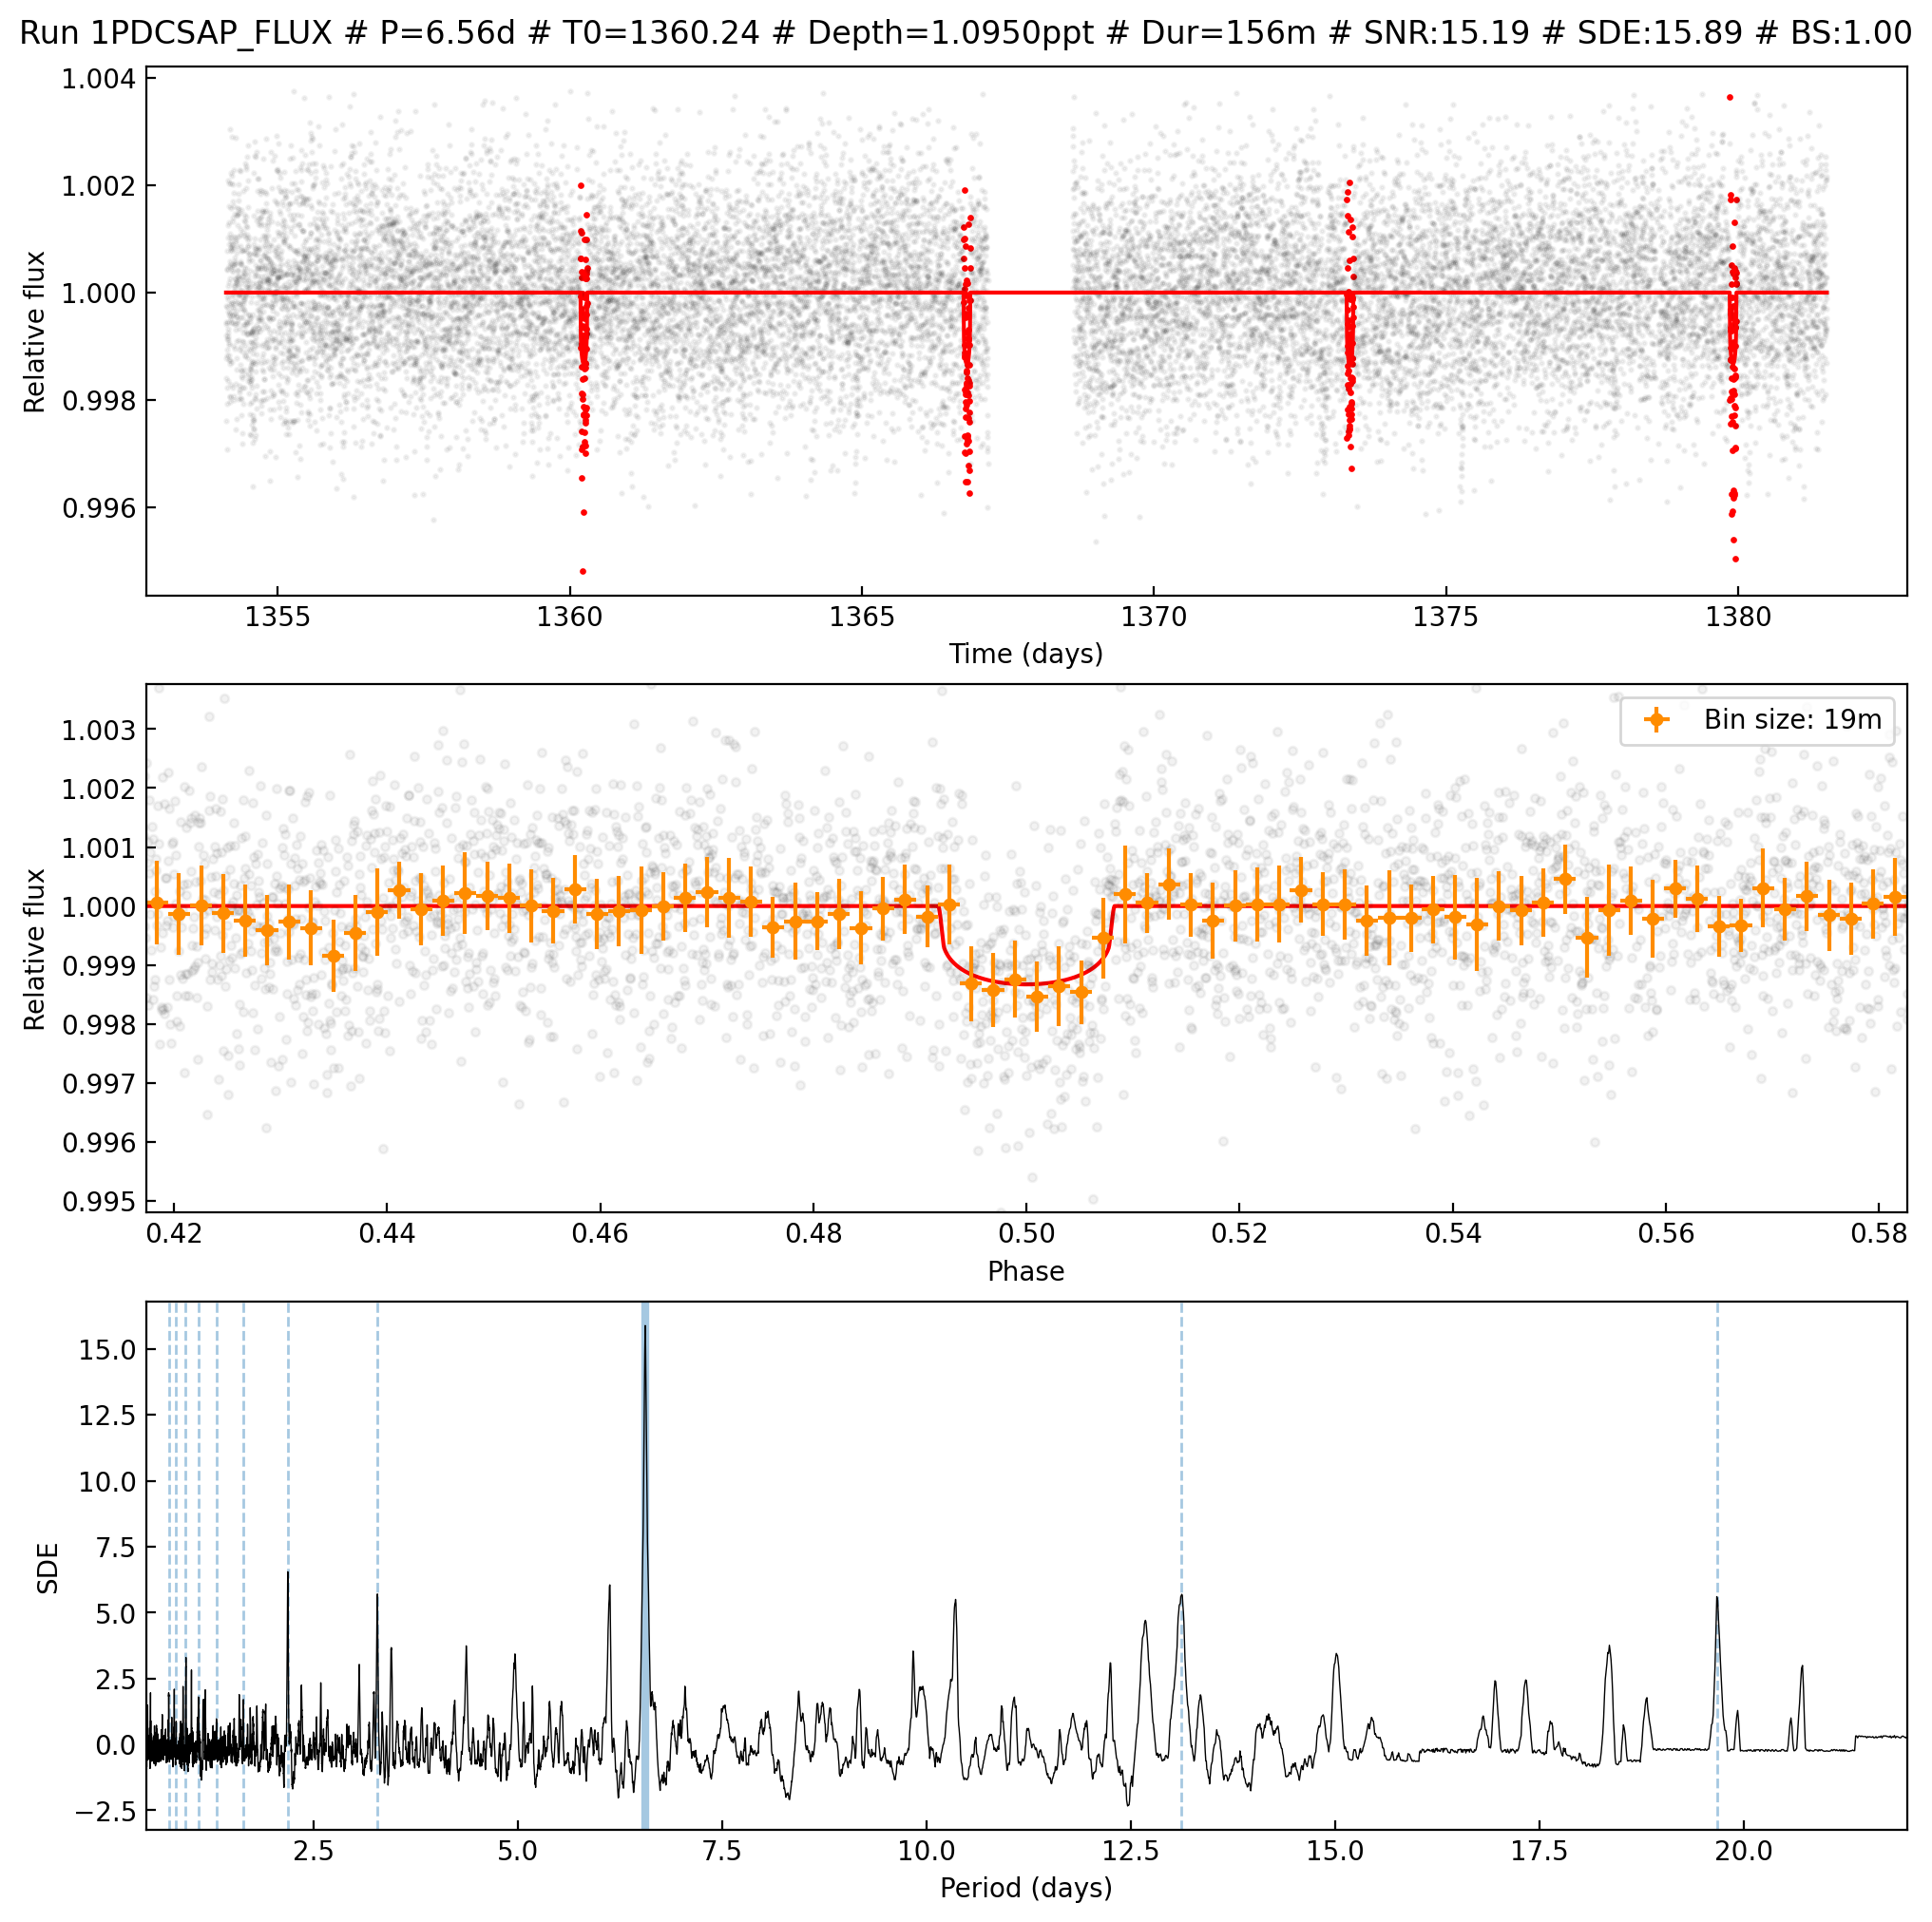

In [7]:
import glob
file_image = sorted(glob.glob(glob.escape(your_execution_dir + '/TIC251848941_[2]') + '/*/*.png'))[0]
from IPython.display import Image
Image(filename=file_image)

There is now a candidate with P=1.92d. That one matches another new confirmed planet from
the authors that wasn't either alerted by the SPOC! And again only from the TESS data.

There is only one promising run to be analyzed already, but we don't expect finding more
confirmed planets as the one with 15.5 days lies out of the period grid finally used by
`Sherlock`:

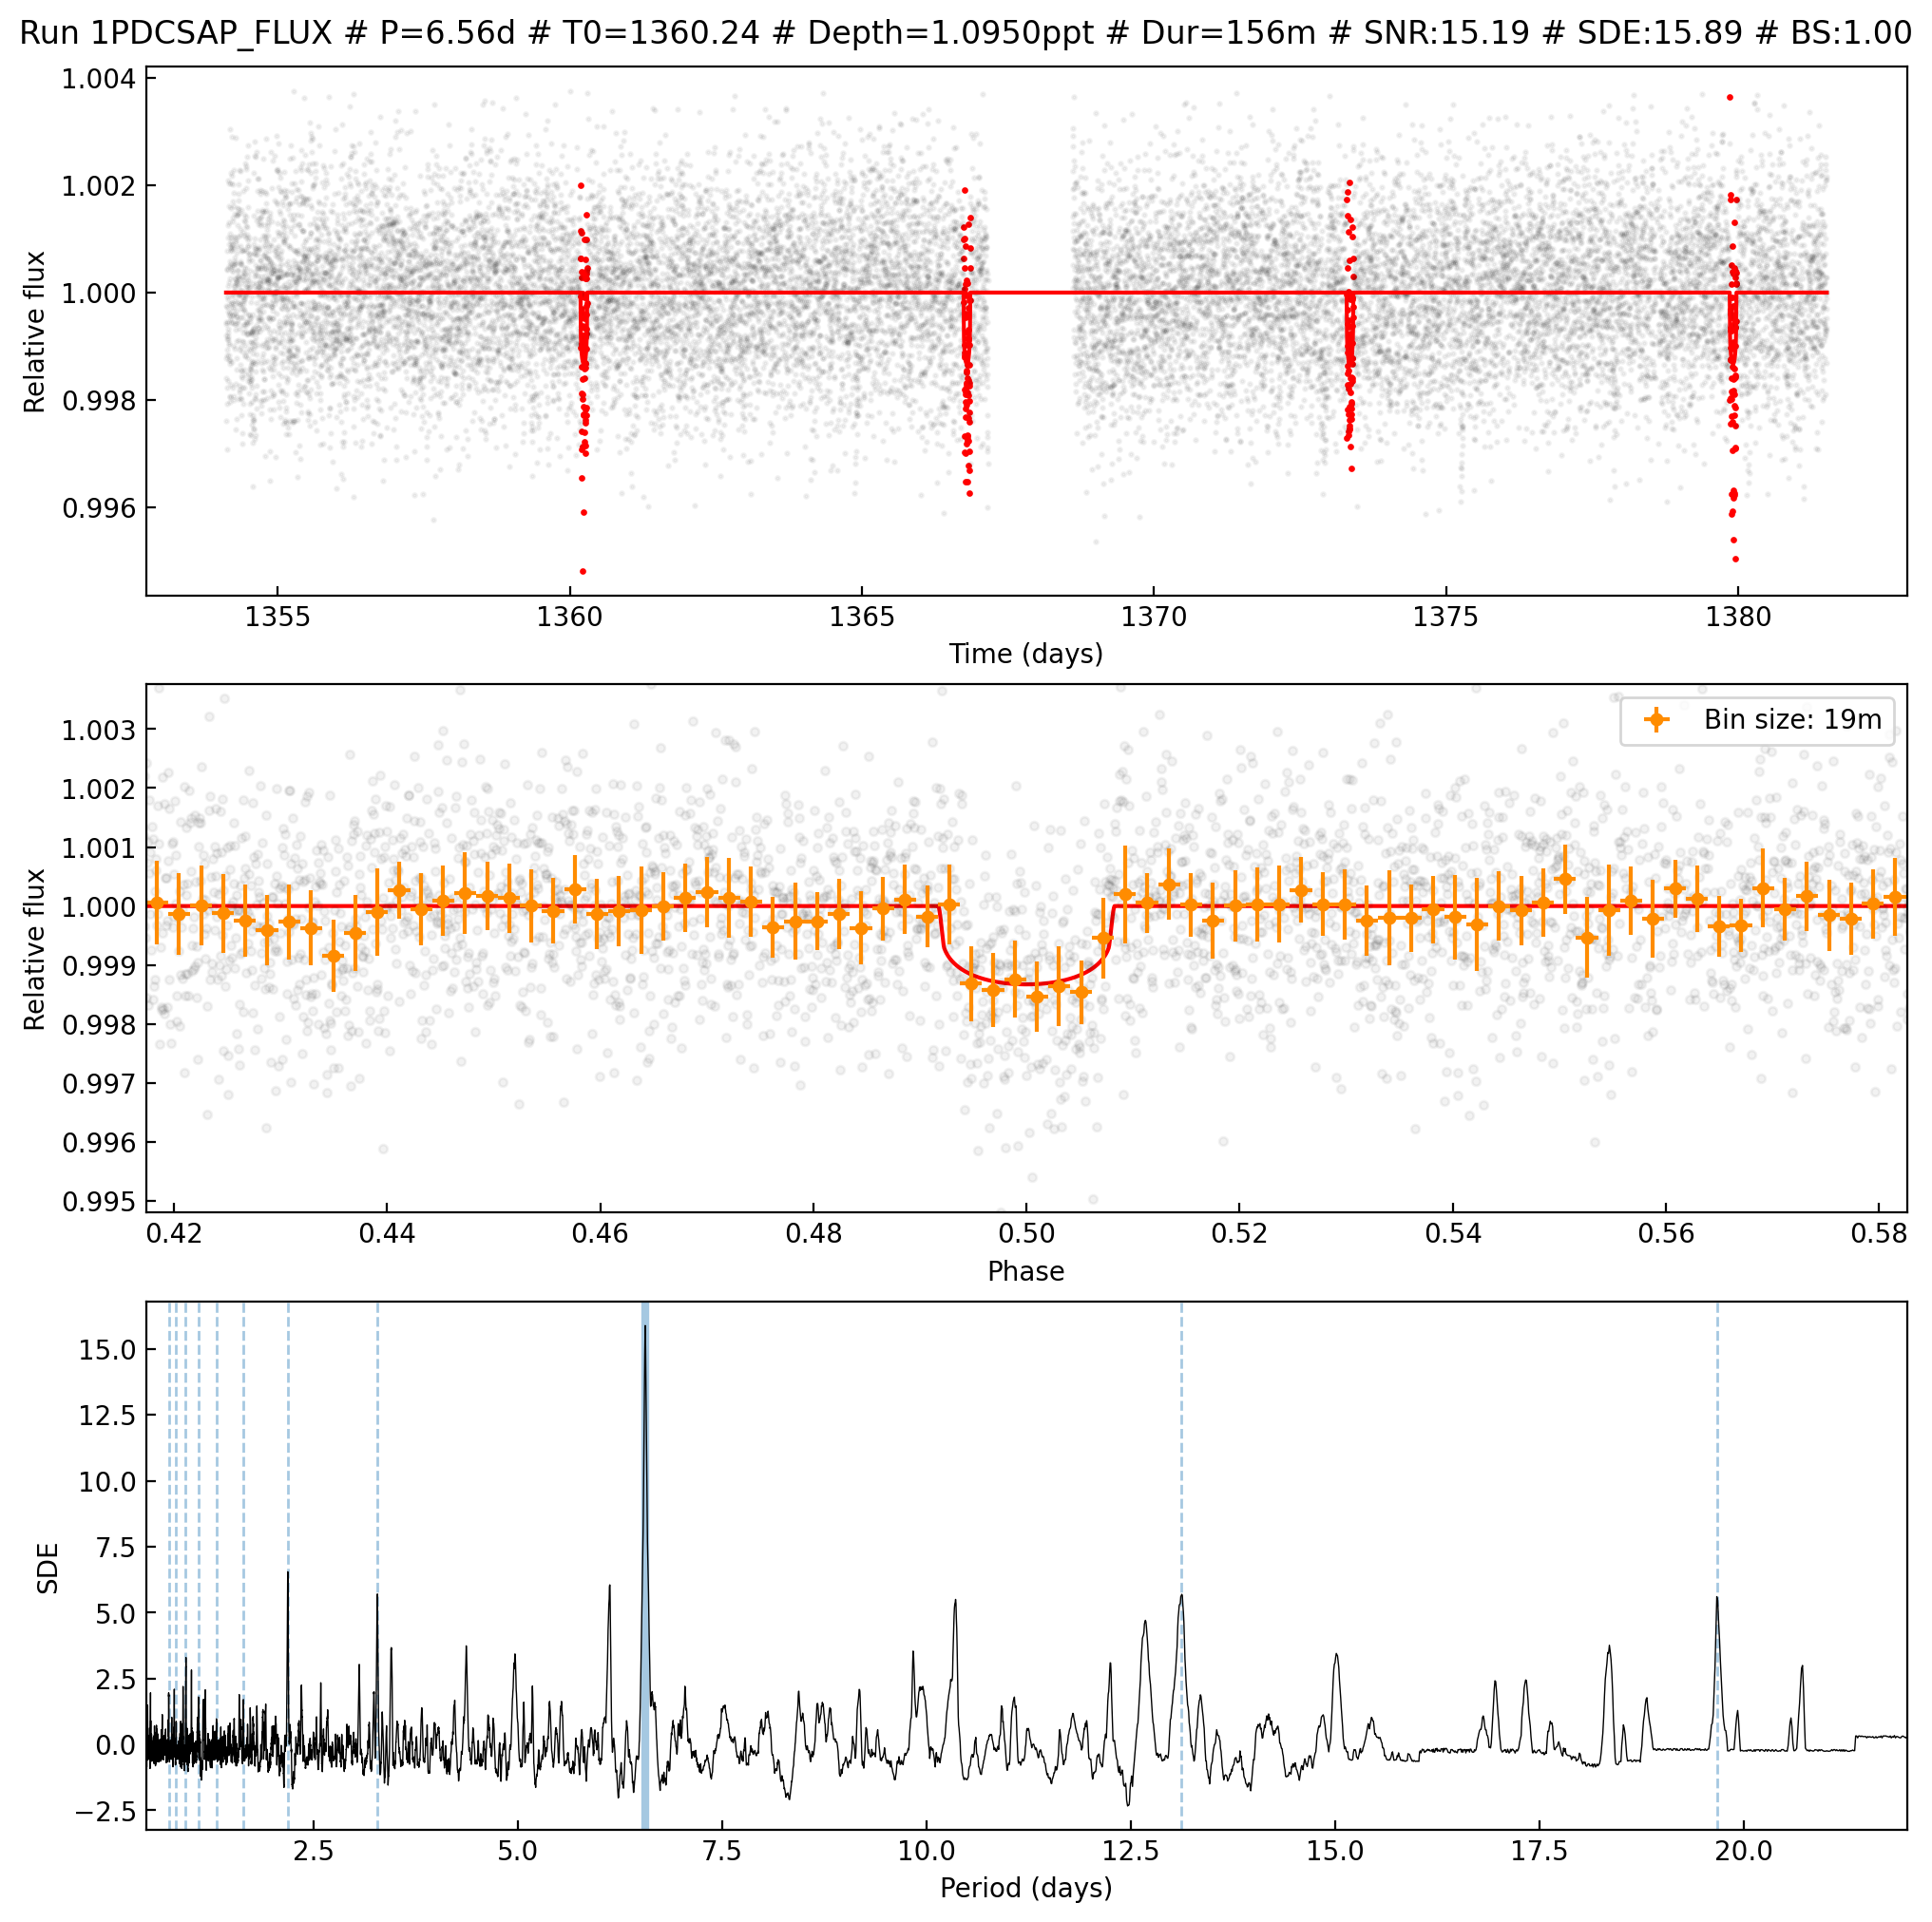

In [8]:
import glob
file_image = sorted(glob.glob(glob.escape(your_execution_dir + '/TIC251848941_[2]') + '/*/*.png'))[0]
from IPython.display import Image
Image(filename=file_image)

It seems that this candidate is not very reliable (it lies on the borders of the data).
The candidates TOI-178.02 and TOI-178.03 are too close. Maybe any of them is a subharmonic
of the real period. We could perform a search now to see whether we find it properly, by setting
a minimum period of 11 and masking the reliable candidates that we found previously:

In [9]:
toi178_object_info.initial_transit_mask = [{"P": 6.5591, "T0": 1360.24, "D": 146.10},
                                            {"P": 4.9628, "T0": 1358.01, "D": 167.02},
                                            {"P": 3.2375, "T0": 1356.10, "D": 123.87},
                                            {"P": 1.9159, "T0": 1354.88, "D": 111.07}]
toi178_sherlock_target = SherlockTarget(object_info=toi178_object_info, detrends_number=4,
                                        period_min=11, period_max=22, cpu_cores=multiprocessing.cpu_count() - 1,
                                        best_signal_algorithm="quorum", min_quorum=0.5)
sherlock = Sherlock([toi178_sherlock_target], False)

DONE


Let's run SHERLOCK again with these parameters!

In [10]:
sherlock.run()

2026-08-16 17:44:28 INFO     SHERLOCK (Searching for Hints of Exoplanets fRom Lightcurves Of spaCe-base seeKers)


2026-08-16 17:44:28 INFO     Version 1.5.1


2026-08-16 17:44:28 INFO     MODE: ANALYSE


2026-08-16 17:44:28 INFO     ID: TIC251848941_[2]


2026-08-16 17:44:28 INFO     ================================================


...

2026-08-16 17:46:12 INFO     0           20.7070   0.04716   136.85    1354.55 1.034   0.112      9.223      9.65    9.41    1.00          TOI 178.02    -           2.31977                  0.03294   0.13002           I                   


2026-08-16 17:46:12 WARNING  /mnt/c/workspace/ph/SHERLOCK/sherlockpipe/search/sherlock.py:400: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  candidates_df = pandas.concat([candidates_df, pandas.DataFrame([report])], ignore_index=True)



2026-08-16 17:46:12 INFO     0           15.2391   0.04703   165.73    1364.91 0.687   0.107      6.397      7.03    7.54    1.00          TOI 178.05    -           1.89070                  0.02719   0.10598           I                   


2026-08-16 17:46:12 INFO     2           11.2517   0.02092   132.98    1355.92 0.736   0.122      6.028      5.22    6.24    0.67                        -           1.95718                  0.02012   0.08658           I                   


2026-08-16 17:46:12 INFO     4           11.8245   0.02794   131.64    1357.47 0.362   0.093      3.910      4.01    4.90    1.00                        -           1.37305                  0.02004   0.08949           I                   


Ok, it already finished. We can see in the report that 3 candidates were found. Let's go to the
inspection!

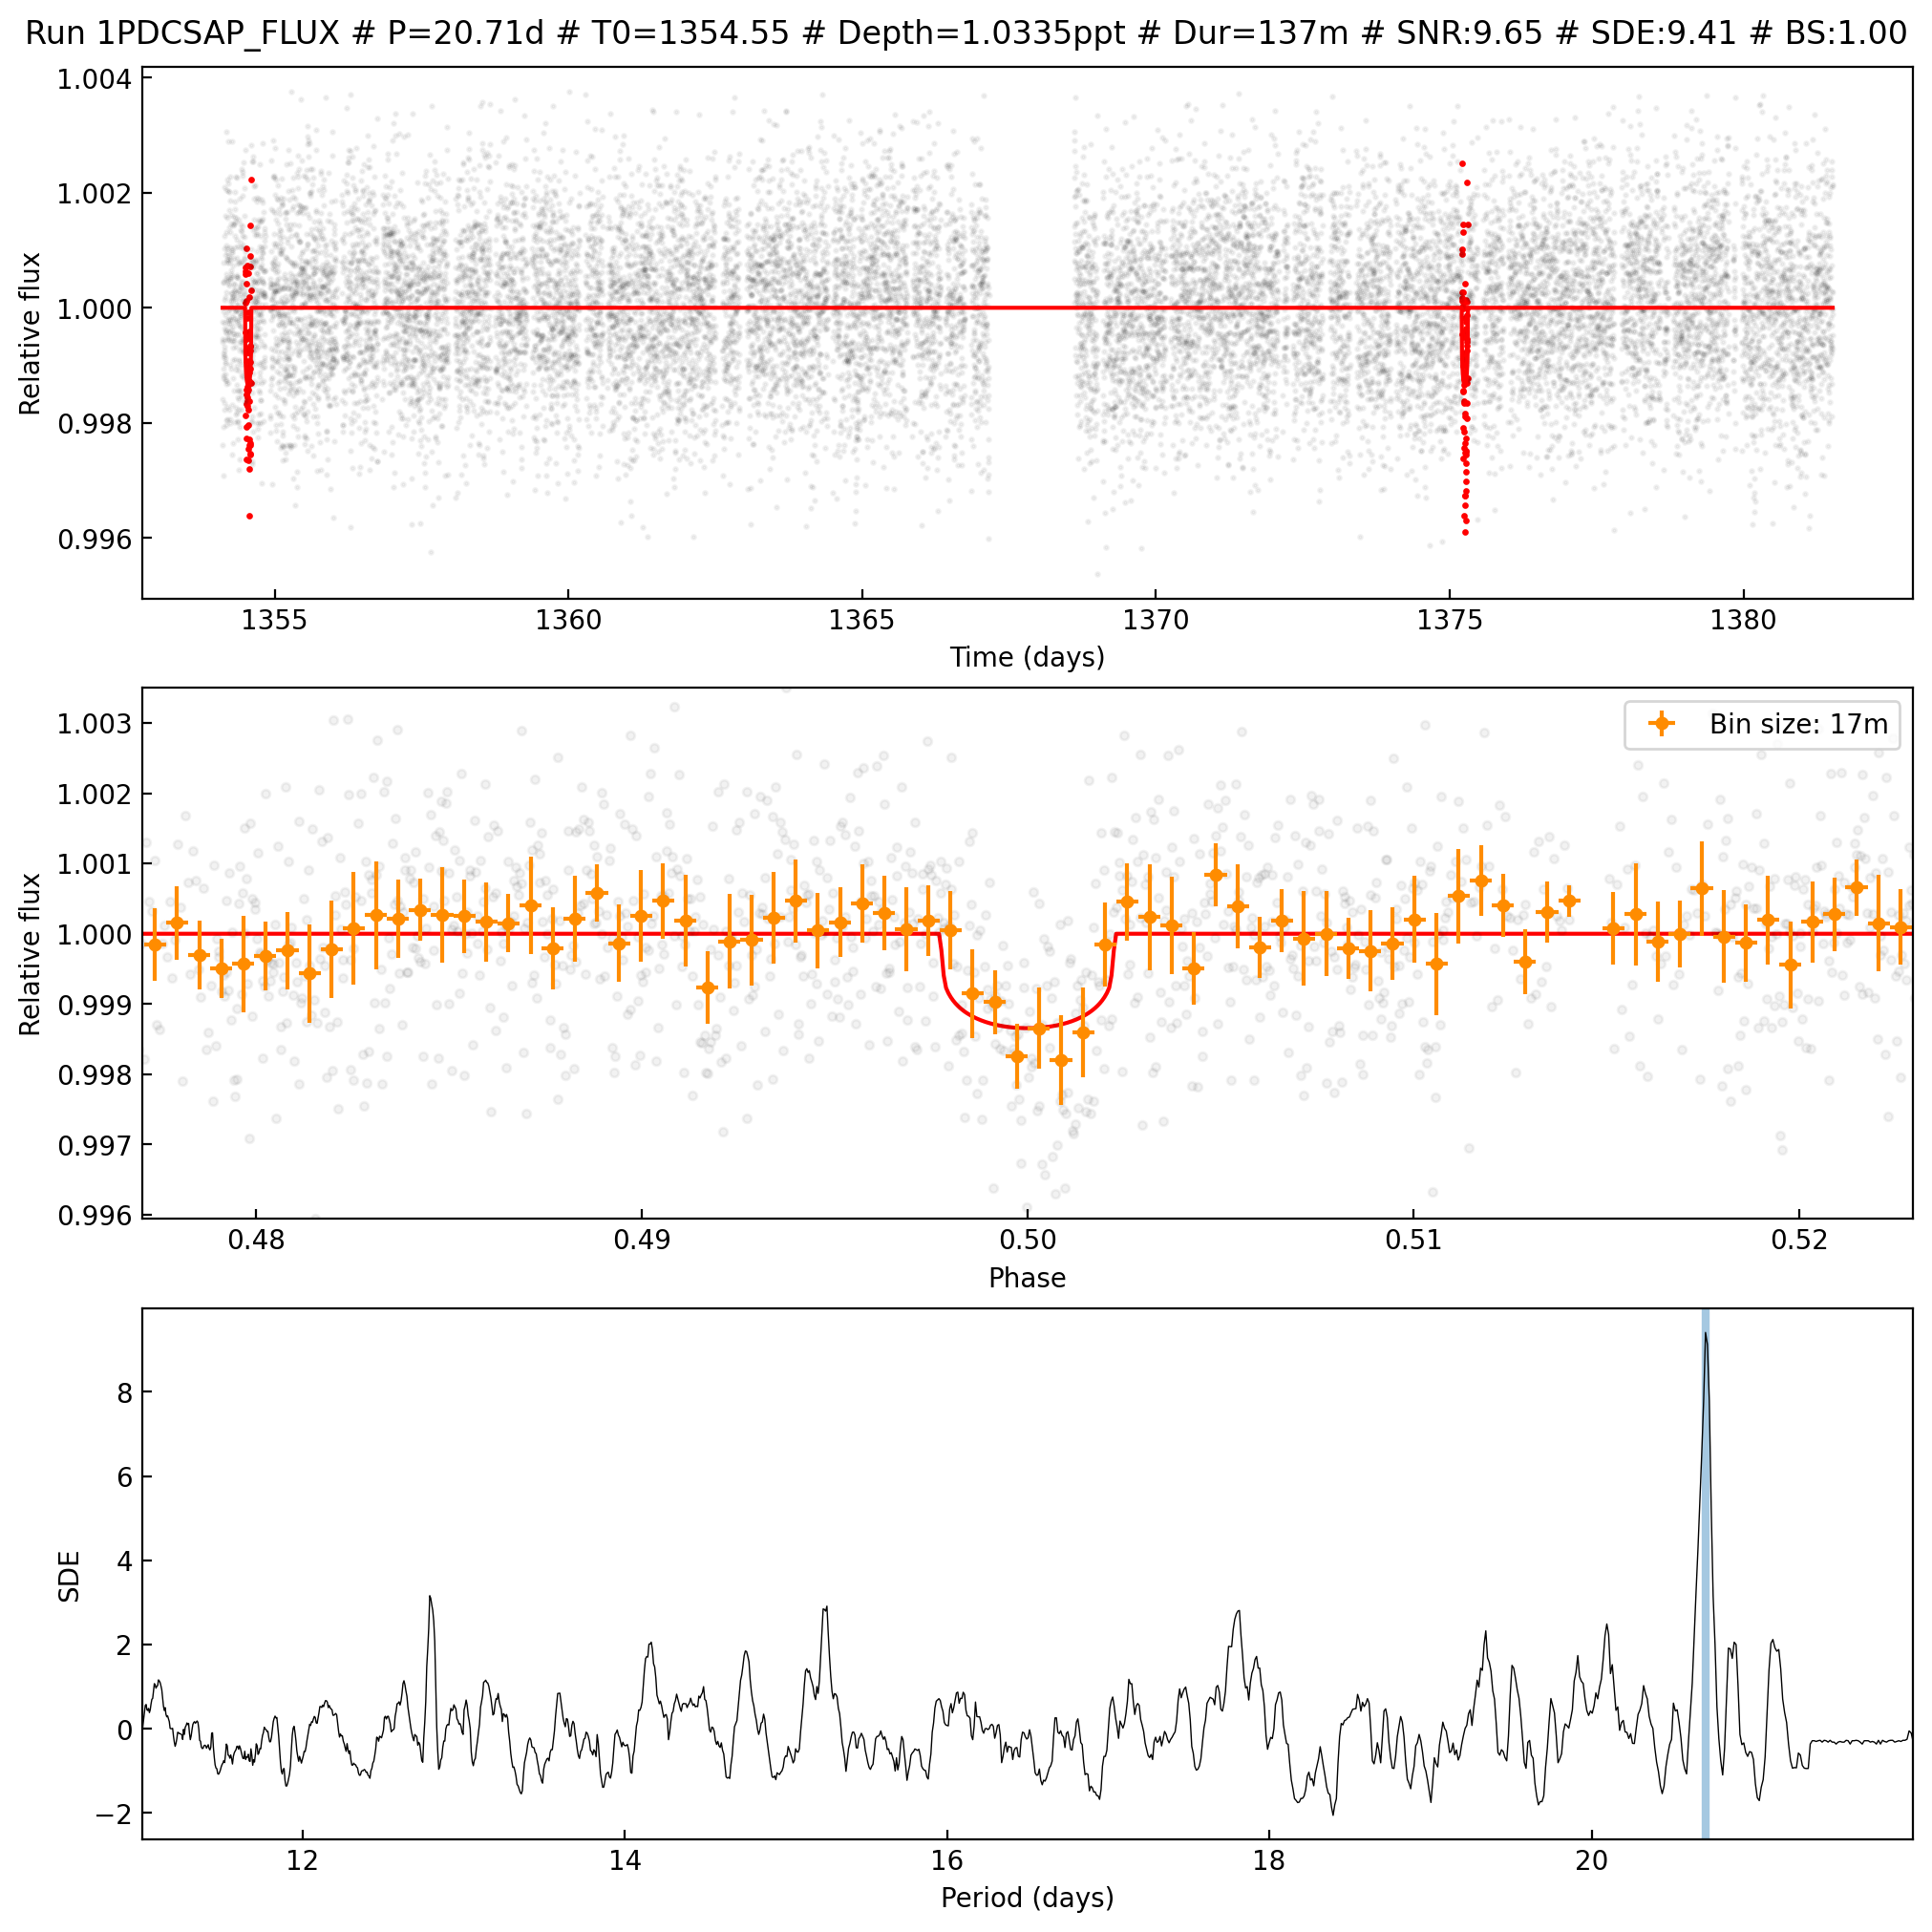

In [11]:
your_execution_dir = os.getcwd()
import glob
file_image = sorted(glob.glob(glob.escape(your_execution_dir + '/TIC251848941_[2]') + '/*/*.png'))[0]
from IPython.display import Image
Image(filename=file_image)

It seems that we have now found the planet at P=20.7d. Looking finally at the last promising candidate:

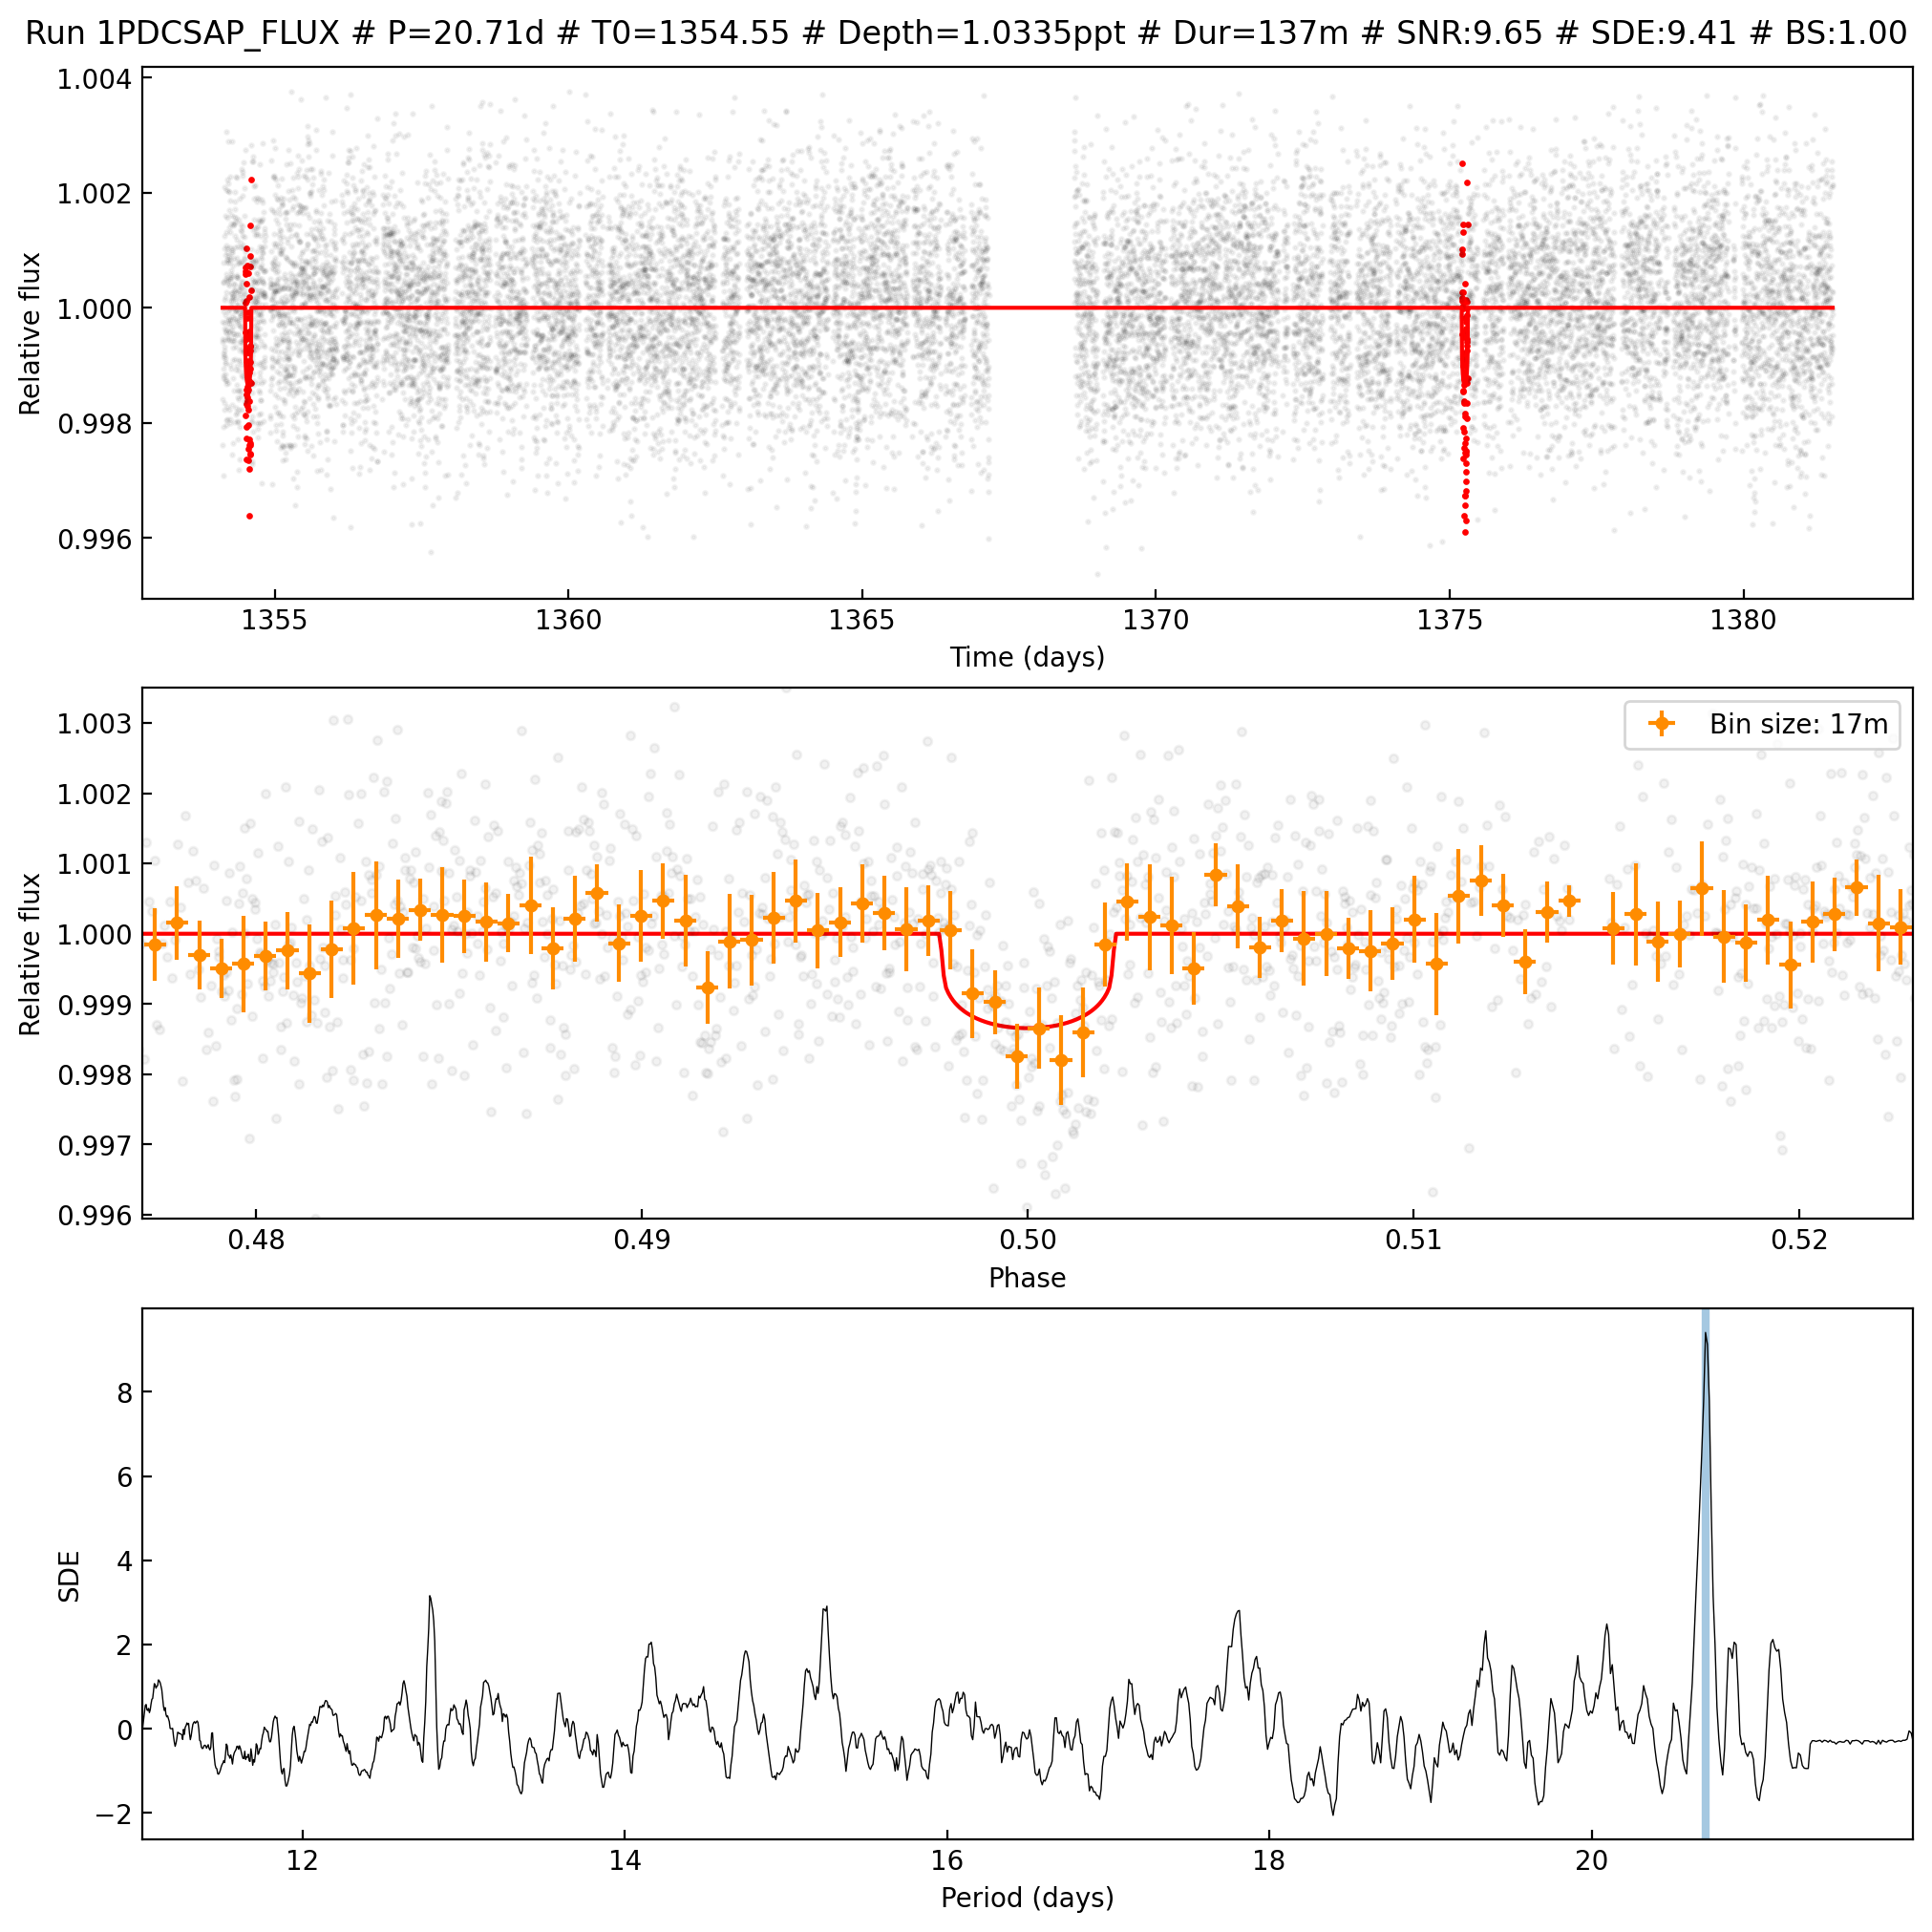

In [12]:
import glob
file_image = sorted(glob.glob(glob.escape(your_execution_dir + '/TIC251848941_[2]') + '/*/*.png'))[0]
from IPython.display import Image
Image(filename=file_image)

And finally found the last one at P=15.21d! Good for SHERLOCK again!

We conclude our analysis here: `SHERLOCK` has been able to spot candidates which were
only identified after precise follow-up observations so far. We can also observe how
the SNRs of the signals found by `SHERLOCK` are way higher than the ones obtained by the
official SPOC pipeline. These are great indicators of the `SHERLOCK` capabilities!